# RIGID + probe: test single images

Plain RIGID compares DINOv2 embeddings of an image and a slightly noisy copy, and keeps only
their cosine similarity. This detector keeps more: it feeds the **clean embedding** and the
**change under noise** (noisy − clean) to a logistic-regression probe trained on labelled real
and AI-generated images. Code: [rigid_probe.py](rigid_probe.py); training:
`scripts/train_final_probe.py`.

**What to expect** (held-out results from `scripts/train_probe.py`):

| test | plain RIGID | this probe (`clean+diff`) |
|---|---|---|
| same dataset, unseen images | 0.60 – 0.88 AUROC | 0.94 – 0.98 |
| unseen generator, same dataset | 0.60 – 0.88 | ~0.90 – 0.93 |
| a different dataset than it was trained on | — | **0.65 – 0.76** |

So it is reliable on images resembling its training data (ImageNet-style photos and
ADM / LDM / BigGAN; RAISE camera photos and the 9 Synthbuster generators) and much weaker
on images from elsewhere. Treat the probability as a hint, not a verdict.

In [1]:
# Reload edited modules (e.g. rigid_probe.py) automatically, without restarting the kernel
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from rigid_probe import ProbeDetector

## Settings

- `IMAGE_PATH`: the image to test.
- `THRESHOLD`: P(AI-generated) at or above this is labelled AI-generated.
- `N_NOISE`: noise draws averaged per image. The probe's output varies between draws, so use several (8 is a good default).

In [9]:
IMAGE_PATH = "test_images/real/IMG_1255.JPG"   # <-- set this

MODEL = "mlp"        # "logreg" (logistic regression) or "mlp" (small neural network)
PROBE_PATH = {"logreg": "model/DINOv2/Frozen DINO model/probes/probe_clean_diff.joblib",
              "mlp": "model/DINOv2/Frozen DINO model/probes/probe_clean_diff_mlp.joblib"}[MODEL]
THRESHOLD = 0.0715
N_NOISE = 8
DEVICE = None           # None = auto (cuda > mps > cpu)

## Load the detector (run once)

In [3]:
detector = ProbeDetector(PROBE_PATH, device=DEVICE, threshold=THRESHOLD)
m = detector.meta
print(f"Running on {detector.device}")
print(f"Probe: {m.get('model', 'logreg')}, features={m['features']}, trained on {m['datasets']} "
      f"({m['n_real']} real + {m['n_fake']} fake images)")
print("Generators seen in training:", ", ".join(s for s in m["sources"] if s not in ("imagenet", "raise")))
print(f"DINOv2 {m['model_name']}, input {m['image_size']}px, noise λ = {m['lamb']}")

Using cache found in /Users/michael/.cache/torch/hub/facebookresearch_dinov2_main


Running on mps
Probe: mlp, features=clean+diff, trained on ['imagenet', 'synthbuster'] (5914 real + 14674 fake images)
Generators seen in training: adm, biggan, dalle2, dalle3, firefly, glide, ldm, midjourney-v5, stable-diffusion-1-3, stable-diffusion-1-4, stable-diffusion-2, stable-diffusion-xl
DINOv2 dinov2_vitl14, input 224px, noise λ = 0.05


## Test the image

Change `IMAGE_PATH` above and re-run the settings cell and this cell.

P(AI-generated) = 0.052 (± 0.025)  ->  REAL (threshold 0.07)  |  plain RIGID similarity = 0.9843


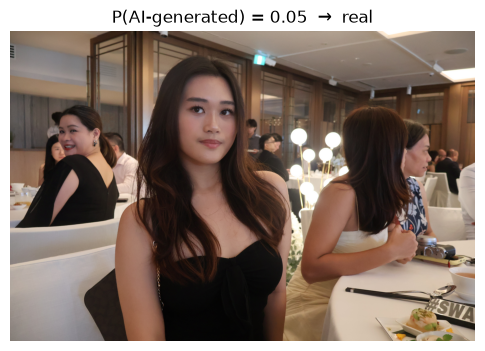

In [10]:
detector.threshold = THRESHOLD
result = detector.predict(IMAGE_PATH, n_noise=N_NOISE)
print(result)

plt.figure(figsize=(6, 6))
plt.imshow(Image.open(IMAGE_PATH).convert("RGB"))
plt.title(f"P(AI-generated) = {result.p_fake:.2f}  →  {result.label}")
plt.axis("off")
plt.show()

## Optional: test a whole folder

Scores every image in `FOLDER` (including subfolders) and lists them from most to least likely
AI-generated.

In [5]:
FOLDER = "/Volumes/Kioxia SSD/datasets/kagglehub/datasets/rhythmghai/ai-vs-real-images-dataset/versions/1/real_dataset"        # e.g. "test_images/real"
MAX_IMAGES = 50

if FOLDER:
    exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
    files = sorted(p for p in Path(FOLDER).expanduser().rglob("*")
                   if p.suffix.lower() in exts and ".ipynb_checkpoints" not in p.parts)[:MAX_IMAGES]
    rows = []
    for p in files:
        r = detector.predict(p, n_noise=N_NOISE)
        rows.append({"image": p.name, "p_ai_generated": round(r.p_fake, 3), "label": r.label,
                     "rigid_similarity": round(r.rigid_similarity, 4)})
    table = pd.DataFrame(rows).sort_values("p_ai_generated", ascending=False)
    print(table["label"].value_counts().to_string())
    display(table)
else:
    print("Set FOLDER to score a folder of images.")

label
real            41
ai-generated     9


,image,p_ai_generated,label,rigid_similarity
46,animals_14.jpg,0.985,ai-generated,0.9791
21,animals_117.jpg,0.974,ai-generated,0.9861
6,animals_103.jpg,0.943,ai-generated,0.9938
33,animals_128.jpg,0.935,ai-generated,0.9886
11,animals_108.jpg,0.930,ai-generated,0.9958
16,animals_112.jpg,0.838,ai-generated,0.9958
22,animals_118.jpg,0.837,ai-generated,0.9777
45,animals_139.jpg,0.819,ai-generated,0.9946
20,animals_116.jpg,0.811,ai-generated,0.9932
28,animals_123.jpg,0.726,real,0.9950


## Find the best cutoff

AUROC measures the probe over *all* cutoffs, so it can't pick one by itself. This cell scores
labelled images you provide and reports three standard choices:

| criterion | picks the cutoff that… | use when |
|---|---|---|
| **Youden's J** (balanced accuracy) | maximizes fakes caught − real images wrongly flagged | default; both mistakes equally bad |
| **Max F1** (AI-generated = positive) | best balances precision and recall for catching fakes | you mainly care about catching fakes *and* your folders' real/fake mix matches real use |
| **Fixed false-positive rate** | catches the most fakes while flagging at most `TARGET_FPR` of real images | wrongly accusing a real image is costly |

Use images the probe was **not trained on**, ideally similar to what you will test (same source,
size, compression). Aim for at least 30–50 of each; with only a handful the cutoff is very noisy.

In [6]:
import random

import numpy as np
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve
from tqdm import tqdm

REAL_FOLDER = "/Volumes/Kioxia SSD/datasets/coco_ai/real"
FAKE_FOLDER = "/Volumes/Kioxia SSD/datasets/coco_ai/fake/sd35"


MAX_PER_FOLDER = 400
TARGET_FPR = 0.05                   # for the fixed-false-positive-rate cutoff

EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
def list_images(folder):
    """All images under `folder`; if more than MAX_PER_FOLDER, a random sample (fixed seed)
    so every subfolder (e.g. each generator) is represented, not just the first one."""
    files = sorted(p for p in Path(folder).expanduser().rglob("*")
                   if p.suffix.lower() in EXTS and ".ipynb_checkpoints" not in p.parts)
    if len(files) > MAX_PER_FOLDER:
        files = sorted(random.Random(0).sample(files, MAX_PER_FOLDER))
    return files

real_files, fake_files = list_images(REAL_FOLDER), list_images(FAKE_FOLDER)
print(f"{len(real_files)} real, {len(fake_files)} fake images")
if min(len(real_files), len(fake_files)) < 30:
    print("⚠ Fewer than 30 images in a class: treat the cutoffs below as rough.")

# Warn if any of these images were used to train the probe (cutoff would be too optimistic).
emb_dir = Path("results/embeddings")
if emb_dir.exists():
    trained = {Path(str(p)).name for f in emb_dir.glob("*.npz") for p in np.load(f)["path"]}
    overlap = [p.name for p in real_files + fake_files if p.name in trained]
    if overlap:
        print(f"⚠ {len(overlap)} image name(s) match training images, e.g. {overlap[:3]}")

files = real_files + fake_files
y = np.r_[np.zeros(len(real_files)), np.ones(len(fake_files))]          # 1 = AI-generated
scores = np.array([detector.predict(p, n_noise=N_NOISE).p_fake for p in tqdm(files, desc="Scoring")])

400 real, 400 fake images


Scoring: 100%|████████████████████████████████████████████████████████████████| 800/800 [08:20<00:00,  1.60it/s]


AUROC on these images: 0.841



,cutoff,fakes caught (TPR),real flagged (FPR),balanced acc,precision,F1,accuracy
Youden's J (balanced accuracy),0.0715,0.775,0.225,0.775,0.775,0.775,0.775
Max F1 (AI-generated positive),0.0715,0.775,0.225,0.775,0.775,0.775,0.775
FPR <= 5%,0.4155,0.460,0.050,0.705,0.902,0.609,0.705
Current THRESHOLD,0.7834,0.245,0.005,0.620,0.980,0.392,0.620


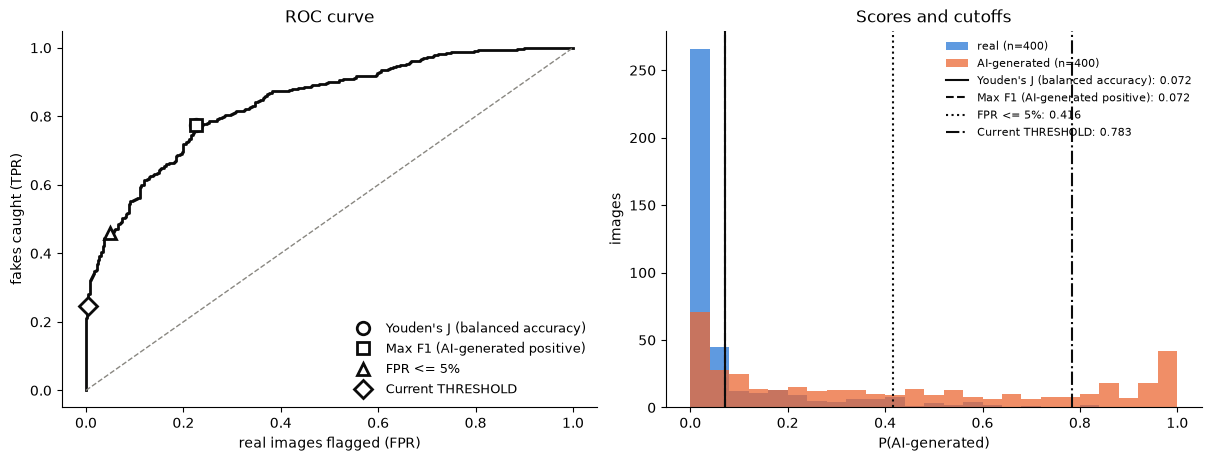

In [7]:
def metrics_at(t):
    pred = scores >= t
    tp, fp = int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum())
    fn, tn = int((~pred & (y == 1)).sum()), int((~pred & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return {"cutoff": round(float(t), 4),
            "fakes caught (TPR)": round(rec, 3),
            "real flagged (FPR)": round(fp / (fp + tn) if fp + tn else 0.0, 3),
            "balanced acc": round(0.5 * (rec + (tn / (tn + fp) if tn + fp else 0.0)), 3),
            "precision": round(prec, 3),
            "F1": round(2 * prec * rec / (prec + rec) if prec + rec else 0.0, 3),
            "accuracy": round((tp + tn) / len(y), 3)}

fpr, tpr, roc_t = roc_curve(y, scores)            # predict AI-generated when score >= threshold
roc_t = np.clip(roc_t, 0, 1)                      # first threshold is +inf ("flag nothing")
prec, rec, pr_t = precision_recall_curve(y, scores)
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)

cutoffs = {
    "Youden's J (balanced accuracy)": roc_t[np.argmax(tpr - fpr)],
    "Max F1 (AI-generated positive)": pr_t[np.argmax(f1)],
    f"FPR <= {TARGET_FPR:.0%}": roc_t[np.where(fpr <= TARGET_FPR)[0][-1]],
    "Current THRESHOLD": THRESHOLD,
}
print(f"AUROC on these images: {roc_auc_score(y, scores):.3f}\n")
display(pd.DataFrame({name: metrics_at(t) for name, t in cutoffs.items()}).T)

# Plots: ROC curve with the chosen points, and score distributions with the cutoffs
REAL_C, FAKE_C, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
a1.plot(fpr, tpr, color=INK, lw=2)
a1.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
for (name, t), mk in zip(cutoffs.items(), ["o", "s", "^", "D"]):
    m = metrics_at(t)
    a1.plot(m["real flagged (FPR)"], m["fakes caught (TPR)"], mk, ms=9, color=INK, mfc="white", mew=2, label=name)
a1.set(xlabel="real images flagged (FPR)", ylabel="fakes caught (TPR)", title="ROC curve")
a1.legend(frameon=False, fontsize=9, loc="lower right")
bins = np.linspace(0, 1, 26)
a2.hist(scores[y == 0], bins=bins, color=REAL_C, alpha=0.75, label=f"real (n={int((y == 0).sum())})")
a2.hist(scores[y == 1], bins=bins, color=FAKE_C, alpha=0.75, label=f"AI-generated (n={int(y.sum())})")
for (name, t), ls in zip(cutoffs.items(), ["-", "--", ":", "-."]):
    a2.axvline(t, color=INK, ls=ls, lw=1.5, label=f"{name}: {t:.3f}")
a2.set(xlabel="P(AI-generated)", ylabel="images", title="Scores and cutoffs")
a2.legend(frameon=False, fontsize=8)
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)
plt.show()

To use a cutoff, copy its value into `THRESHOLD` in the settings cell (or run
`detector.threshold = <value>`), then re-run the test cells.